## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Kate rodriguez, Yorleny aguilar Juan Jose Garcia" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


# 1) Descripción del problema **[1 pts]**

Una plataforma de red social desea analizar las conexiones de amistad entre sus usuarios. Cada usuario será representado mediante un vértice y cada amistad mediante una arista.

El objetivo es implementar recorridos BFS y DFS y utilizar BFS para encontrar conexiones con la menor cantidad de saltos.



## 2) Requerimientos **[2 pts]**

**RF_1:** Se debe epresentar la red social como un grafo no dirigido usando una lista adyacente.

**RF_2:** Se debe imprimir cada usuario de la red junto con us contactos directos.

**RF_3:** Se debe ejecutar un recorrido BFS desde un usuario especifico, mostrando el orden de visita y agrupando a los contactos por su grado de separacion.

**RF_4:** Se debe ejecutar un recorrido DFS desde un usuario especifico explorando a profundidad.

**RF_5:** Se debe permitir buscar la ruta más corta entre un usuario inicial y uno destino, utilizando BFS:

**RF_6:** Validar la existencia de los ususarios antes de iniciar cualquier recorrido y mostrar mensajes de error apropiados si no existen.

**RF_7;** Se debe permitir agregar un nuevo usuario al sistema y conectarlo al menos con dos usuarios existentes, actualizando el grafo.

**RNF_1:** El lenguaje de programacion será python.

**RNF_2:** La implementacion BFS debe realizarse utilizando una estructura de datos tipo pila:

**RNF_3:** La implementacion de DFS debe realizarse utilizando recursividad o estructura tipo pila.

**RNF_4:** No se pueden usar librerias que implementen BFS o DFS o estructuras de grafos.







## 3) Historias de usuario **[2 pts]**
**HU_1:** Como analista de datos, quiero visualizar la estructura dela red mediante una lista de adyacencia para verificar rapidamente quíen es amigo directo de quíen.

***Criterios de aceptacion:*** El sistema debe imprimir el nombre de cada usuario seguido de la lista de sus conexiones. Cada amistad se almacena en ambos sentidos sin duplicados.

**HU_2**: Como usuario de la plataforma, quiero buscar el camino más corto para conectar con una persona que no conozco, para saber qué amigos en común nos pueden presentar.

***Criterios de aceptacion:*** El sistema solicita el usiario origen y destino. Retorna la ruta paso a paso y el numero exacto de grados deseparacion. Si no hay conexion, muestra un mensaje.

**HU_3:** Como administrador, quiero registrar a un nuevo usuario llamado Juliana y enlazarla con sus amigos, para mantener la red social actualizada.

***Criterios de aceptacion:*** Se registra al nuevo usuario en la lista de adyacencia y se generan las conexiones bidireccionales con los contactos indicados. Los algoritmos BFS y DFS siguen funcionando correctamente con un nuevo grafo.



## 4) Diagramas de flujo **[5 pts]**
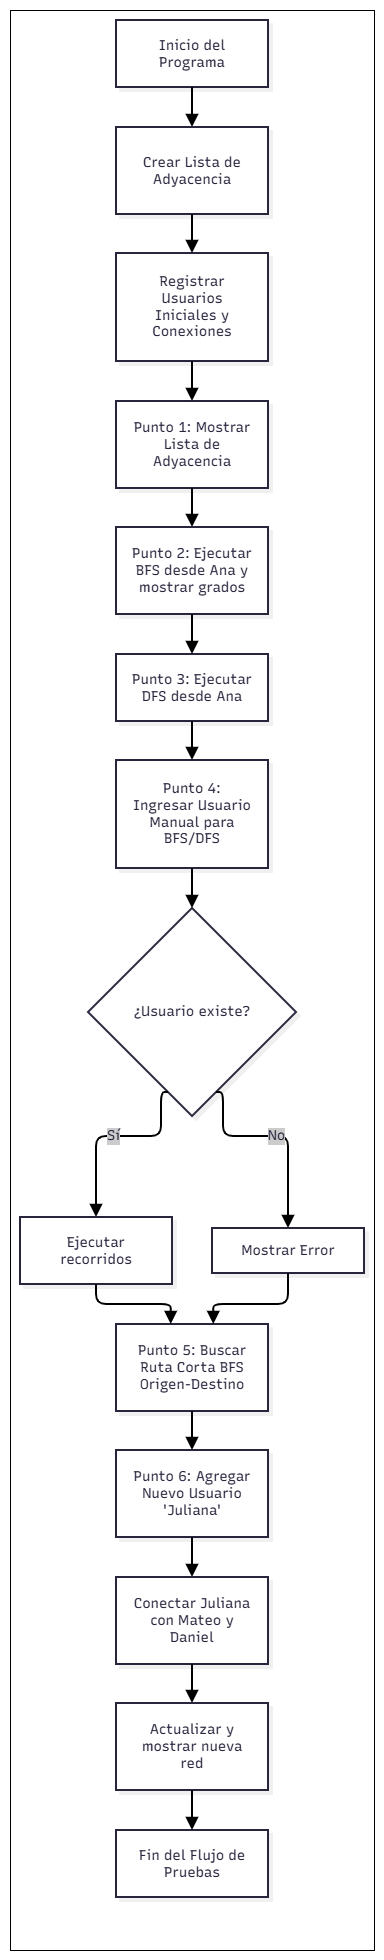

### 5) Análisis de complejidad **[15 pts]**
Para la representación del grafo nos fuimos por listas de adyacencia. Básicamente, esto nos permite acceder a los vecinos de cualquier usuario de forma directa y sin dar vueltas.Si te fijas en cómo funcionan el BFS o el DFS aquí, la clave de todo está en la estructura de nodos visitados.

Gracias a eso garantizamos que cada vértice $V$ entra a la cola (o a la pila) una única vez. Lo mismo pasa con las conexiones: cada arista $E$ la evaluamos solo dos veces, una por cada extremo, al tratarse de un grafo no dirigido.

Como no estamos repitiendo trabajo ni haciendo recorridos de más, el tiempo de ejecución termina siendo simplemente proporcional a la cantidad de datos que tenemos.En términos de complejidad, esto nos deja un $T(n)$ de $O(\vert{}V\vert{} + \vert{}E\vert{})$, donde $\vert{}V\vert{}$ son los vértices (usuarios) y $\vert{}E\vert{}$ las aristas (amistades). Y como la búsqueda de la ruta más corta la montamos directamente sobre ese mismo BFS, hereda este rendimiento exacto.

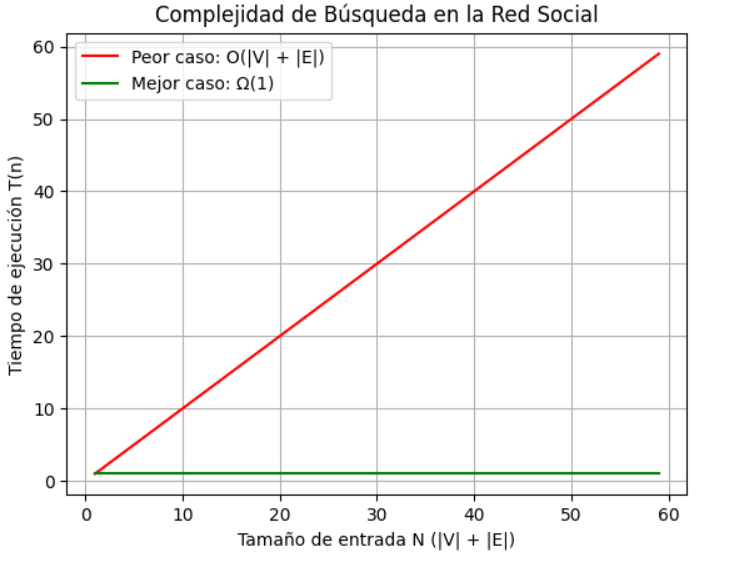Por cierto, un detalle de la implementación: al manejar todo esto por debajo con diccionarios de Python (que en el fondo actúan como hash maps), agregar nuevos nodos o aristas nos sale prácticamente "gratis", manteniendo un tiempo de inserción de $O(1)$ amortizado.

## 6) Código funcional **[15 pts]**


In [19]:
from collections import deque
class RedSocial:
   def __init__(self):
       self.amigos = {}
   def agregar(self, nombre):
       if nombre not in self.amigos:
           self.amigos[nombre] = []
   def unir(self, p1, p2):
       self.agregar(p1)
       self.agregar(p2)
       if p2 not in self.amigos[p1]:
           self.amigos[p1].append(p2)
       if p1 not in self.amigos[p2]:
           self.amigos[p2].append(p1)
   def mostrar(self):
       for persona in self.amigos:
           lista = ", ".join(self.amigos[persona])
           print(persona + ": " + lista)
   def bfs(self, inicio):
       if inicio not in self.amigos:
           print(inicio + " no existe")
           return [], {}
       vistos = [inicio]
       cola = deque()
       cola.append((inicio, 0))
       resultado = []
       grados = {}
       while len(cola) > 0:
           actual, grado = cola.popleft()
           resultado.append(actual)
           if grado not in grados:
               grados[grado] = []
           grados[grado].append(actual)
           for amigo in self.amigos[actual]:
               if amigo not in vistos:
                   vistos.append(amigo)
                   cola.append((amigo, grado + 1))
       return resultado, grados
   def dfs(self, inicio):
       if inicio not in self.amigos:
           print(inicio + " no existe")
           return []
       vistos = []
       pila = [inicio]
       resultado = []
       while len(pila) > 0:
           actual = pila.pop()
           if actual not in vistos:
               vistos.append(actual)
               resultado.append(actual)
               for amigo in self.amigos[actual]:
                   if amigo not in vistos:
                       pila.append(amigo)
       return resultado
   def camino(self, inicio, fin):
       if inicio not in self.amigos or fin not in self.amigos:
           print("Falta uno de los dos")
           return []
       vistos = [inicio]
       cola = deque()
       cola.append([inicio])
       while len(cola) > 0:
           ruta = cola.popleft()
           ultimo = ruta[-1]
           if ultimo == fin:
               return ruta
           for amigo in self.amigos[ultimo]:
               if amigo not in vistos:
                   vistos.append(amigo)
                   nueva = ruta + [amigo]
                   cola.append(nueva)
       return []

## 7) Tests aplicados **[15 pts]**

In [20]:

red = RedSocial()
parejas = [
   ("Ana", "Carlos"),
   ("Ana", "Laura"),
   ("Carlos", "Mateo"),
   ("Carlos", "Sofia"),
   ("Laura", "Daniel"),
   ("Sofia", "Valentina"),
   ("Daniel", "Valentina")
]
for a, b in parejas:
   red.unir(a, b)
print("Red:")
red.mostrar()
print()
print("BFS desde Ana:")
orden, grados = red.bfs("Ana")
print(orden)
print("Grados de separacion:")
for g in grados:
   print("Grado " + str(g) + ": " + ", ".join(grados[g]))
print()
print("DFS desde Ana:")
print(red.dfs("Ana"))
print()
print("Camino de Ana a Valentina:")
ruta = red.camino("Ana", "Valentina")
if ruta:
   print(ruta)
   print("Pasos:", len(ruta) - 1)
else:
   print("No hay camino")
print()
print("Agrego a Juliana")
red.unir("Juliana", "Mateo")
red.unir("Juliana", "Daniel")
print()
print("Camino de Ana a Juliana:")
ruta2 = red.camino("Ana", "Juliana")
if ruta2:
   print(ruta2)
   print("Pasos:", len(ruta2) - 1)

Red:
Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofia
Laura: Ana, Daniel
Mateo: Carlos
Sofia: Carlos, Valentina
Daniel: Laura, Valentina
Valentina: Sofia, Daniel

BFS desde Ana:
['Ana', 'Carlos', 'Laura', 'Mateo', 'Sofia', 'Daniel', 'Valentina']
Grados de separacion:
Grado 0: Ana
Grado 1: Carlos, Laura
Grado 2: Mateo, Sofia, Daniel
Grado 3: Valentina

DFS desde Ana:
['Ana', 'Laura', 'Daniel', 'Valentina', 'Sofia', 'Carlos', 'Mateo']

Camino de Ana a Valentina:
['Ana', 'Carlos', 'Sofia', 'Valentina']
Pasos: 3

Agrego a Juliana

Camino de Ana a Juliana:
['Ana', 'Carlos', 'Mateo', 'Juliana']
Pasos: 3
